# 线性回归与训练循环

---
## 模型到底在预测什么
#### 1. "回归"要解决什么问题?
**回归 (regression)**: 根据输入, 预测一个有数量意义的数值. 例如根据房屋面积, 房龄预测价格.

与它对照的是**分类 (classification)**: 判断属于哪个类别, 例如判断图片是鞋子还是衣服. 即使类别用数字`0, 1, 2`编码, 也不因此变成回归.

我们用下面这条虚拟数据贯穿讲解:
<table>
<tr><th>面积</th><th>房龄</th><th>实际成交价</th></tr>
<tr><td>80平方米</td><td>10年</td><td>175万元</td></tr>
</table>

先认识这些术语:
- **样本 (sample)**: 一个具体案例. 这里一套房子的这条记录就是一个样本.
- **数据集 (dataset)**: 许多样本组成的集合.
- **特征 (feature)**: 用于预测的输入. 这里是面积和房龄.
- **标签 (label) 或目标 (target)**: 实际模型预测的已知答案. 这里是实际成交价.
- **预测值 (prediction)**: 模型实际算出的答案, 不保证与标签相同.

所以, 这条样本可以写成:
$$x = [80, 10], \;\;\;\;\; y = 175$$
`x`是输入, `y`是已知答案; 预测值通常记作$\hat{y}$, 读作"y hat".

#### 2. 模型是一套带着可调参数的计算规则
**模型 (model)**: 把输入转换成预测值的计算规则.

先只使用面积:
$$\hat{y} = w x + b$$

这里:
- **权重 (weight)** `w`: 决定输入在计算中乘以多少.
- **偏置 (bias)** `b`: 加权计算完成后, 额外加上的数.
- **参数 (parameter)**: 模型中准备通过训练调整的数值. 这里就是`w`和`b`.

假设我们先手动设定`w=2, b=20`, 输入面积`80`:
$$\hat{y} = 2\times 80 + 20 = 180$$

模型预测180万元, 标签是175万元. 两个值不同完全正常.

注意: 这里的参数是我们暂时指定的, 还不是训练学到的. 后面训练要做的, 就是根据数据调整参数.

#### 3. 多个特征, 每个特征对应一个权重
把房龄也加入模型:
$$\hat {y} = w_1x_1 + w_2x_2 + b$$

假设:
$$w_1 = 2, \;\;\; w_2 = -1, \;\;\; b = 20$$

对刚才那套房子:
$$\hat{y} = 2\times 80 - 1\times 10 + 20 = 170$$

这个模型里, 保持面积不变, 房龄每增加一年, 预测价格减少一万元. 这是这套公式表达的关系, 不是在证明现实中的因果关系.

如果有`d`个特征, 就有`d`个权重; 再加一个偏执, 共`d + 1`个可训练参数. 向量写法只是把同一件事写成:
$$\hat{y} = \mathbf{w^T} \mathbf{x} + b$$

其中$\mathbf{w^T} \mathbf{x}$就是学过的点积. 这里输入和标签是给定的数据, 权重和偏执才是本项目准备学习的参数.

#### 4. 为什么它也是一个简单神经网络?
把计算过程看成:
```
多个输入 → 分别乘权重 → 相加并加偏置 → 一个输出
```

这个计算单元可以称为一个**人工神经元 (artificial neuron)**. 每个输入都连接到输出, 这样的计算层叫**全连接层 (fully connected layer)**, 也叫稠密层.

这里没有中间的隐藏层, 通常也不把输入本身算作计算层, 因此它是一个**单层网络**. 它是简单的数学模型, 不等于在真实模拟大脑.

再补一个术语边界: 严格数字意义上的线性变换要求零输入得到零输出; 加入非零偏置后, 叫**仿射变换 (affine transformation)**. 知道这个区别即可, 不必因此纠结"线性回归"这个约定名称.

---
## 怎样判断预测好不好

#### 1. 预测误差: 预测值与标签相差多少

我们约定:
$$e = \hat{y} - y$$
其中`e`是**预测误差 (prediction error)**

比如标签是`16`:
- 预测`19`, 误差是`+3`, 表示预测偏高.
- 预测`15`, 误差是`-1`, 表示预测偏低.

这里的正负表示方向, 不是正数就好, 负数就不好. 预测是否接近, 要看误差大小.



#### 2. 为什么不能直接平均这些误差?
假设有两条样本:
<table>
<tr><th>样本</th><th>标签</th><th>预测值</th><th>误差</th></tr>
<tr><td>A</td><td>16</td><td>19</td><td>+3</td></tr>
<tr><td>B</td><td>16</td><td>13</td><td>-3</td></tr>
</table>
平均误差为:
$$\frac{3 + (-3)}{2} = 0$$
但模型显然没有预测准确, 只是高估与低估抵消了.

所以我们需要一种不会让正负误差相互抵消的评分方式.

#### 3. 平方损失与均方误差

**损失函数 (loss function)**: 把预测与标签转换成一个数值, 用来衡量预测有多不符合目标. 训练时, 我们希望降低这个数值.

一种方式是把误差平方:
$$(\hat {y} - y)^2$$

于是, 误差`+3`和`-3`都得到`9`, 不会抵消. 误差大小从`1`变成`2`时, 平方损失从`1`变成`4`, 因此它对较大的误差惩罚更重.

**均方误差 (Mean Squared Error, MSE)**, 就是把多个样本的平方误差取平均:
$$MSE = \frac{1}{n}\sum_{i = 1}^{n}(\hat {y} - y)^2$$

这里`n`是样本数量, $\sum$表示把这些项加起来.

刚才两条样本的MSE就是:
$$\frac{3^2 + (-3)^2}{2} = 9$$

注意: MSE为`9`, 不是说平均差了9万元, 单位也平方了; 现在先把它理解成用于比较和优化的评分.

#### 4. 为什么D2L公式里还有一个`1/2`?

教材把单个样本损失写成:
$$l = \frac 1 2 (\hat y - y)^2$$

再对样本取平均. 这样得到的平均损失就是MSE的一半.

乘`1/2`是为了求导方便: 平方根求导产生的`2`恰好被消掉. 它不会改变哪一组参数使损失最小, 但**会改变梯度的大小**, 因此比较代码时不能忽略它.

在PyTorch中, 可以这样对应:

In [ ]:
errors = predictions - targets
squared_errors = errors ** 2

mse = squared_errors.mean()
d2l_loss = squared_errors.mean() / 2

这里先记住: 取平均的除数与教材额外乘的`1/2`, 是两个不同来源.

---
## 为什么教材会把正态分布与平方损失联系起来?

#### 1. 真实数据通常不会严格落在一个公式上
假设某个理想关系:
$$y = 2x + 1$$

当`x = 3`时, 理想结果是`7`. 但实际测量可能得到`6.8`, `7.1`, `7.05`.

这些偏差可能来自测量误差, 或公式没有包含其他因素. 我们用**噪声 (noise)** 表示它:
$$y = 2x + 1 + \epsilon$$

$\epsilon$读作"epsilon", 这里代表噪声. 例如实际结果为`6,8`, 本次噪声就是`-0.2`.

注意: **噪声是数据生成过程中的扰动; 预测误差还可能包含模型参数不准确造成的偏差**. 两者不能直接划等号.

#### 2. 正态分布是在描述"噪声怎样出现"

**正态分布 (normal distribution)**, 也叫**高斯分布 (Gaussian distribution)**, 是一种常见的钟形分布.

先认识三个量:
- **均值 (mean)** $\mu$: 分布的中心位置.
- **标准差 (standard deviation)** $\sigma$: 描述分布有多分散, 越大通常越宽.
- **方差 (variance)** $\sigma^2$: 标准差的平方.

教材假设噪声的均值为零. 大白话是:
```
"噪声围绕零波动, 小幅扰动更常见, 大幅扰动较少; 不会长期只往正方向或负方向偏"
```

写成:
$$\epsilon \sim \mathcal N(0, \sigma^2)$$

$\sim$在这里读作"服从", $\mathcal N$表示正态分布.

#### 3. 参数好不好, 还可以从"能否解释数据"来判断

假设观察到了一个标签`10`:
- 模型A预测`9.9`, 只需要一个很小的噪声就能解释这个观测.
- 模型B预测`30`, 需要一个很大的噪声才能解释它.

在相同的零均值高斯噪声假设下, A对这个观测的解释更合理.

**似然 (likelihood)**: 固定已经观察到的数据, 比较不同参数对这些数据提供的支持程度.

**极大似然估计 (maximum likelihood estimation)**: 选择让已观察数据的似然最大的参数.

严格说, 这里对连续数值使用的是**概率密度**, 不是"恰好出现这个数的概率". 当前先记住: 它提供了一种比较参数的评分方式.

#### 4. 为什么最后又变回平方误差?

在**各样本噪声相互独立, 都服从相同方差的零均值正态分布, 并把方差视为固定值** 的条件下, 教材经过变换, 得到:
$$负对数似然 = C + \frac{1}{2\sigma^2}\sum_{i}(y_i - \hat{y_i})^2$$

这句话里的新词可以这样理解:
- **对数 (logarithm)**: 这里用于把多个评分的乘积变成求和, 方便处理.
- **负号**: 把"最大化评分"改成"最小化评分".
- `C`: 与我们正在调整的权重, 偏置无关的部分.

因此, 改变权重和偏置时, 真正需要降低的就是后面的**平方误差总和**. 样本数量固定时, 最小化总和与最小化平均值, 会得到相同的最优参数.


---
## 参数为什么会朝正确方向改变.

#### 1. 梯度不是新参数, 而是更新的依据

你已经知道, `loss.backward()`会得到:
$$\frac{\partial L}{\partial w}, \;\;\; \frac{\partial L}{\partial b}$$

它们表示: **在当前参数附近, 参数稍微变化时, 损失怎样变化.**

以一个参数为例:
- 梯度为正: 参数稍微增加, 损失倾向于增加.
- 梯度为负: 参数稍微增加, 损失倾向于减少.

所以, 要降低损失, 我们尝试朝**负梯度方向**移动. 这种逐步调整参数的方法叫**梯度下降 (gradient descent)**.

但这里说的是局部变化: 一部走得太大, 仍然可能把损失变高.

#### 2. 学习率控制走多大一步

**学习率 (learning rate)**: 控制每次沿负梯度方向移动多少的数, 代码中常叫`lr`, 公式中写成$\eta$, 读作"eta".

更新规则是:
$$w_新 = w_旧 - \eta\frac{\partial L}{\partial w}$$
$$b_新 = b_旧 - \eta\frac{\partial L}{\partial b}$$

注意是**减去梯度乘学习率**, 如果梯度为负, "减负数"就会让参数增加.

这里也能区分:
- `w, b`是**参数 (parameters)**: 通过训练更新.
- 学习率是**超参数 (hyperparameter)**: 控制训练方式的设置; 当前由我们指定, 不是本模型通过反向传播学出的.

#### 3. 完整手算一次更新

只有一条样本:
$$x = 2, \;\;\; y = 6$$

模型和损失为:
$$\hat {y} = w x + b, \;\;\; L = \frac 1 2 (\hat y - y)^2$$

初始参数设为`w = 1, b = 0`.

先前向计算:
$$\hat {y} = 1\times2 + 0 = 2, \;\;\; L = \frac 1 2 (2 - 6)^2 = 8$$

再用链式法则求梯度:
$$\frac {\partial L}{\partial w} = (\hat y - y)x = (-4)\times 2 = -8$$
$$\frac {\partial L}{\partial b} = \hat y - y = -4$$

为什么权重梯度多乘一个`x`? 因为$\hat y = w x + b$, 对`w`求导得到`x`, 对`b`求导得到`1`.

设学习率为`0.1`, 用**更新前算出的同一组梯度**更新两个参数:
$$w_新 = 1 - 0.1 \times (-8) = 1.8$$
$$b_新 = 0 - 0.1 \times (-4) = 0.4$$

最后重新预测, 检查效果:
$$\hat {y_新} = 1.8 \times 2 + 0.4 = 4$$
$$L_新 = \frac 1 2 (4 - 6)^2 = 2$$

**损失从`8`降到了`2`. 这就是一次训练更新: 算预测 -> 算损失 -> 算梯度 -> 改参数**. 这里只改善了一条样本, 还不能说明整个数据集都变好了.

#### 4. 与Autograd对上

这次计算中:
- `.backward()`负责得到`-8, -4`.
- 更新规则负责把参数从`1, 0`改成`1.8, 0.4`.
- 下一次预测必须用新的参数重新计算, 旧的预测不会自动变成新预测值.

---
## 补齐batch, epoch, 小批量SGD, 以及解析解与迭代优化的区别

#### 1. 为什么不每次都看完整个数据集?

刚才我们只用一条样本计算梯度. 真实训练通常有很多样本, 可以采用不同方式:
<table>
<tr><th>方式</th><th>每次更新使用多少数据</th></tr>
<tr><td>全批量梯度下降</td><td>整个训练集</td></tr>
<tr><td>严格意义上的随机梯度下降SGD</td><td>随机选一个样本</td></tr>
<tr><td>小批量随机梯度下降</td><td>一小批样本</td></tr>
</table>

**SGD是Stochastic Gradient Descent**, 即随机梯度下降. 实际应用中, 也经常把小批量版本简称为SGD; PyTorch的`torch.optim.SGD`同样可以用于小批量训练.

小批量的好处是: **不用等整个数据集计算完, 才能更新一次; 同时又能利用张量运算, 一起处理多个样本**.

#### 2. 一个batch中, 怎样总和多个样本的梯度?

**批次 (batch)**: 本次一起处理的一组样本.

**批量大小 (batch size)**: 这组样本的数量.

我们通常根据**该批次的平均损失**计算梯度. 它等价于: 先计算每个样本的梯度, 再取平均.

例如, 两个样本分别给出权重梯度:
```
样本A: 2
样本B: 6
```

那么平均梯度是:
$$g_w = \frac{2 + 6}{2} = 4$$

再用它更新:
$$w_新 = w_旧 - \eta \times 4$$

代码里有两种对应写法:
- 对损失取`.mean()`后反向传播, 更新时不再除以批次大小.
- 对损失取`.sum()`后反向传播, 更新时除以**本批实际样本数**.

平均只做一次, 不要重复除. 这里的批量平均, 与平方损失前面的`1/2`仍然是不同的事情.



#### 3. batch, 训练步和epoch有什么区别?

**训练步 (training step)**: 在我们当前采用的流程里, 处理一个batch, 计算梯度, 并更新一次参数.

**轮次 (epoch)**: 把整个训练集遍历一遍.

例如有`10`条样本, `batch_size=4`, 不丢弃最后不足一批的数据:
```
第 1 批：4 条 → 更新一次
第 2 批：4 条 → 更新一次
第 3 批：2 条 → 更新一次
```

所以:
- `1 epoch`有`3`个batch, 更新`3`次.
- `2 epoch`更新`6`次
- 通常每轮重新打乱样本顺序, 但图片与标签仍保持配对.

这里的"每个batch更新一次"是我们当前的训练设置; 不是所有训练程序都必须如此.

#### 4. 为什么名字里有"随机"?

小批量中的样本会影响梯度, 而每个批次只代表整个数据集的一部分. 随机抽样或打乱后分批, 会使各次更新使用不同的数据组合.

因此, 一次更新可能改善当前batch, 却暂时让另一个batch的损失变大.

**不能要求每一步的全训练集损失都下降, 也不能只凭一个batch的损失判断训练成功.** 后面会结合整体损失曲线和评估观察结果.

#### 5. 解析解与迭代优化

**解析解 (analytical solution)**: 在适用条件下, 通过明确的数学公式求出最优参数.

例如只用一个常数`b`预测`[2, 4, 6]`, 要让平方误差之和最小, 可以直接求出`b=4`, 即寻找更好的结果.

线性回归可以用解析方法求解, 但一般神经网络通常没有这样可直接使用的公式. 所以我们借线性回归, 学习更通用的训练流程. 目前知道区别即可, 不要求推到矩阵求逆公式.

---
## 准备数据, 并让形状对得上

#### 1. 为什么先自己生成数据?

**合成数据 (synthetic data)**: 根据我们指定的规则, 用程序生成的数据.

这次采用教材中的关系:
$$y = 2x_1 - 3.4x_2 + 4.2 + \epsilon$$

所以真实参数是:
$$\mathbf{w}_{true} = [2, -3, 4], \;\;\; b_{true} = 4.2$$

好处是: 我们知道答案, 可以检查训练是否学到了接近真实值的参数.

这里必须分清两套参数:
- **真实参数**: 用于生成数据, 保持固定.
- **待训练数据**: 后面另外初始化, 让模型通过数据学习.

不能直接把真实参数交给模型当作训练成果.

#### 2. 把许多样本排成一个矩阵

生成`1000`条样本, 每条样本有`2`个特征, 得到:
```
features.shape = (1000, 2)

                特征1  特征2
第1条样本         …      …
第2条样本         …      …
……
第1000条样本      …      …
```

因此:
- **每一行是一条样本.**
- **每一列是一种特征.**

用大写`X`表示整个矩阵; 小写`x`通常表示一条样本.

**矢量化 (vectorization)**: 用一次张量运算表达许多样本的计算, 而不是在Python中逐条计算.

比如:
```
raw_y = features @ true_w + true_b
```
就同时算出了`1000`条样本的理想结果.

#### 3. 对照代码看每一步

In [1]:
import torch

torch.manual_seed(42)

true_w = torch.tensor([2.0, -3.4])
true_b = 4.2

features = torch.randn(1000, 2)

raw_y = features @ true_w + true_b
noise = torch.randn_like(raw_y) * 0.01
labels = (raw_y + noise).reshape(-1, 1)

print("features:", features.shape)
print("true_w:", true_w.shape)
print("raw_y:", raw_y.shape)
print("noise:", noise.shape)
print("labels:", labels.shape)

features: torch.Size([1000, 2])
true_w: torch.Size([2])
raw_y: torch.Size([1000])
noise: torch.Size([1000])
labels: torch.Size([1000, 1])


这里几个操作分别表示:
- **随机种子 (random seed)**: 控制伪随机数生成过程. 在相同环境, 相同调用顺序下, 设置相同种子有助于复现实验.
- `torch.randn(1000, 2)`: 从均值为`0`, 标准差为`1`的正态分布生成特征.
- `randn_like(raw_y)`: 生成与`raw_y`形状相同的标准正态随机数.
- 乘`0.01`: 把噪声的标准差缩小到`0.01`.
- `reshape(-1, 1)`: 排成一列, 行数由PyTorch推断.

**特征也使用正态分布, 是我们方便构造实验的选择, 不是线性回归的强制要求**

#### 4. 最容易混淆的两个形状

本次矩阵乘法是:
$$(1000, 2)@(2, ) --> (1000, )$$

所以`raw_y`是一维张量. 最后我们把带噪声的结果整理为:
```
labels.shape  # (1000, 1)
```

两者都有`1000`个数, 但组织方式不同:
- `(1000, )`: 一维张量.
- `(1000, 1)`: 二维张量, 1000行, 1列.

后面的手写模型会采用列形式输出. **统一标签和预测值的形状, 可以避免减法时发生不符合预期的广播.**

---
## 预测和标签形状不一致, 可能不报错, 却算错损失

#### 1. 两个数对应两个数, 也不一定会逐条相减

假设模型预测完全正确:

In [ ]:
predictions = torch.tensor([[2.0],
                            [4.0]])  # shape (2, 1)

targets = torch.tensor([2.0, 4.0])    # shape (2,)

我们希望得到两条各自的误差, 都是零. 但直接计算:

In [ ]:
errors = predictions - targets

由于**广播 (boardcasting)**, PyTorch会得到:
```
tensor([[ 0., -2.],
        [ 2.,  0.]])
```

形状竟然是`(2, 2)`!

相当于计算了:
$$
A =
\begin{bmatrix}
2-2 & 2-4 \\
4-2 & 4-4
\end{bmatrix}
$$

**每个预测值都和每个标签相减了, 而不是一条样本对应一个标签.**

#### 2. 为什么广播成这个形状?

广播从末尾的轴开始对齐, 可以把两者理解为:
```
predictions： (2, 1)
targets：     (1, 2)  ← 为理解广播，补上一个前导轴
结果：        (2, 2)
```

长度为`1`的轴可以扩展, 因此这个运算合法, 不会报错.

但如果继续求平方误差平均值:

In [ ]:
mse = errors.square().mean()

结果是`2`, 而正确结果本应为`0`.

这就是为什么"**代码能运行"不等于"计算符合我们的意思.**"

#### 3. 先统一形状, 再计算损失

In [ ]:
targets = targets.reshape(-1, 1)

assert predictions.shape == targets.shape

errors = predictions - targets
mse = errors.square().mean()

现在:
```
targets.shape： (2, 1)
errors：        [[0.], [0.]]
mse：           0
```

这也是D2L 3.2.5 自定义损失函数中, 把标签reshape成预测形状的原因. **在这个逐样本, 单输出回归任务里, 我们要确保预测与标签逐条对应.**

---
## 小批量读取, 模型参数初始化, 以及矢量化对比.

#### 1. 打乱的是索引, 特征与标签一起取

对应D2L 3.2.2 读取数据集.

假设随机排列后的样本索引是:
```
[3, 0, 4, 1, 2]
```

每批两条, 就依次取`[3, 0]`, `[4, 1]`, `[2]`. 同一批索引同时用于特征和标签, 它们就不会错配.

下面先认识一个Python术语:

**生成器 (generator)**: 可以逐次提供数据的对象. 函数中的`yeild`会交出当前结果并暂停; 循环再次索取数据时, 从暂停处继续, 而不是重新开始.

In [2]:
def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = torch.randperm(num_examples)

    for start in range(0, num_examples, batch_size):
        batch_indices = indices[start:start + batch_size]
        yield features[batch_indices], labels[batch_indices]

逐行看:
- `rendperm(n)`: 把`0`到`n-1`随机排列, 每个索引出现一次.
- `range(0, n, batch_size)`: 一次找到每批的起点.
- 索引切片超出末尾时, 会自然取到结尾, 因此保留最后不足一批的数据.
- yield每次交出一对`(X_batch, y_batch)`.

教材用`random.shuffle`打乱索引; 这里用`torch.randperm`, 实现的是相同的基本思想.

#### 2. 创建另一套待训练参数

对应D2L 3.2.3-3.2.4

In [ ]:
w = torch.normal(0, 0.01, size=(2, 1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

**初始化 (initialization)**: 为训练参数设置起始值. 这里权重从接近零的随机数开始, 偏置从零开始.

注意它们不是之前生成标签的`true_w, true_b`.

对一个batch做预测:

In [ ]:
predictions = X_batch @ w + b

形状变化为:
```
X_batch       w          预测
(B, 2)   @  (2, 1)  →  (B, 1)
```

这里`B`表示这一批实际有多少条样本. 加上形状为`(1, )`的偏置, 会给每条预测加上同一个数, 结果仍为`(B, 1)`.

#### 3. 矢量化没有改变公式, 只改变计算方式

下面两段表达同一个计算:

In [ ]:
# 逐条样本计算
pred_loop = torch.empty(len(X_batch), 1)
for i in range(len(X_batch)):
    pred_loop[i] = X_batch[i] @ w + b

# 整批计算
pred_vectorized = X_batch @ w + b

矢量化把大量工作交给低层数值库, 减少Python循环开销, 通常更高效; 不是因为减少计算了某些样本.

---
## 从零完成一次真正的训练

继续前面几个部分的`features, labels, data_iter`. 先不用`nn.Linear`或`torch.optim`, 模型, 损失和SGD更新都自己写.

**先把三个部件接起来:**

1. **模型**: `X @ w + b`, 输出形状`(B, 1)`.
2. **逐样本损失**: `(预测 - 标签)² / 2`, 仍是`(B, 1)`.
3. **更新规则**: 参数减去"学习率$\times$梯度", 然后清零梯度.

这次统一采用:
```
loss = losses.mean()
loss.backward()
```

因此, **SGD更新中不再除以batch大小**. 教材采用"求和后反传, 再除以批量大小"; 两种方式再这个单输出任务中对应同一个平均梯度, 不要混用.

两个容易出错的位置:
- 参数初始化放在训练循环外, 不能每轮重置, 否则学到的结果会被覆盖.
- `torch.no_grad()`只包住参数更新和观察结果. 训练时的预测与损失必须记录计算图, 才能反向传播.

我们把梯度清零放在每次更新之后: 初始参数的`.grad`是`None`, 首次反传会生成梯度; 以后每批都使用清零后的梯度.

In [3]:
def linreg(X, w, b):
    return X @ w + b  # TODO：返回预测值


def squared_loss(predictions, targets):
    assert predictions.shape == targets.shape
    return (predictions - targets)**2 / 2  # TODO：返回逐样本的半平方损失，不在这里取平均


def sgd(params, lr):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad  # TODO：原地更新参数，不再除以批量大小
            param.grad.zero_()  # TODO：清零该参数的梯度


# 重新初始化待训练参数，不改变 true_w、true_b
w = torch.normal(0, 0.01, size=(2, 1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

lr = 0.03
batch_size = 128
num_epochs = 30
loss_history = []

for epoch in range(num_epochs):
    for X_batch, y_batch in data_iter(batch_size, features, labels):
        predictions = linreg(X_batch, w, b)  # TODO：调用模型
        losses = squared_loss(predictions, y_batch) # TODO：调用逐样本损失函数
        loss = losses.mean()

        loss.backward()  # TODO：反向传播
        sgd([w, b], lr)  # TODO：调用手写 SGD，更新 w、b 并清零梯度

    with torch.no_grad():
        train_predictions = linreg(features, w, b)
        train_loss = squared_loss(train_predictions, labels).mean()
        loss_history.append(train_loss.item())

    print(f"epoch {epoch + 1}, loss {loss_history[-1]:.6f}")

print("学到的 w:", w.detach().reshape(-1))
print("真实的 w:", true_w)
print("学到的 b:", b.detach())
print("真实的 b:", true_b)

epoch 1, loss 9.942378
epoch 2, loss 6.239696
epoch 3, loss 3.915869
epoch 4, loss 2.458528
epoch 5, loss 1.546395
epoch 6, loss 0.970448
epoch 7, loss 0.610963
epoch 8, loss 0.384724
epoch 9, loss 0.242407
epoch 10, loss 0.152823
epoch 11, loss 0.096464
epoch 12, loss 0.060729
epoch 13, loss 0.038250
epoch 14, loss 0.024147
epoch 15, loss 0.015252
epoch 16, loss 0.009635
epoch 17, loss 0.006112
epoch 18, loss 0.003888
epoch 19, loss 0.002478
epoch 20, loss 0.001586
epoch 21, loss 0.001023
epoch 22, loss 0.000667
epoch 23, loss 0.000441
epoch 24, loss 0.000298
epoch 25, loss 0.000207
epoch 26, loss 0.000150
epoch 27, loss 0.000113
epoch 28, loss 0.000090
epoch 29, loss 0.000075
epoch 30, loss 0.000066
学到的 w: tensor([ 1.9966, -3.3968])
真实的 w: tensor([ 2.0000, -3.4000])
学到的 b: tensor([4.1967])
真实的 b: 4.2


权重误差（学习值 - 真实值）: tensor([-0.0034,  0.0032])
偏置误差（学习值 - 真实值）: tensor([-0.0033])


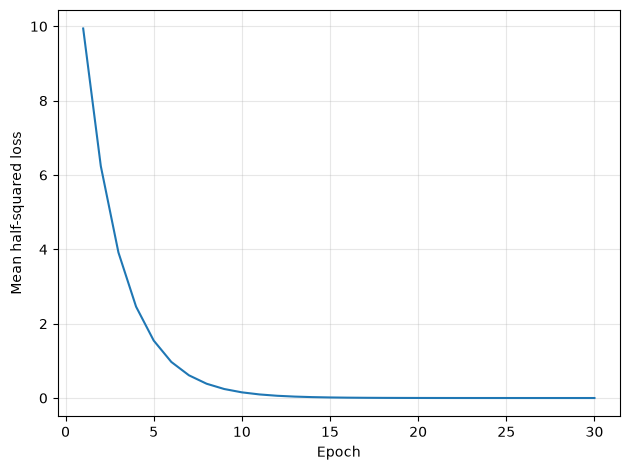

In [4]:
import matplotlib.pyplot as plt

with torch.no_grad():
    w_error = w.reshape(-1) - true_w
    b_error = b - true_b

print("权重误差（学习值 - 真实值）:", w_error)
print("偏置误差（学习值 - 真实值）:", b_error)

plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean half-squared loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## PyTorch简洁实现: 数据读取和模型定义

#### 1. 用`TensorDataset`包装现有数据

我们已经认识了`Dataset`. `TensorDataset`是其中一种: 把已有张量按第一个轴配对, 作为数据集使用.

In [5]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(features, labels)
loader = DataLoader(dataset, batch_size=128, shuffle=True)

这里两者分工是:
- `TensorDataset`: 负责"第i条特征对应的第i条标签"
- `DataLoader`: 负责打乱, 分批, 逐批提供数据, 替代手写的`data_iter()`

它不是把特征和标签拼成一个大矩阵, 例如:
```
x_sample, y_sample = dataset[0]
```

相当于分别取`feature[0]`和`labels[0]`, 形状是`(2, )`, `(1, )`. 包装的张量需要有相同的样本数量.

#### 2. 用`nn.Module`替代手写模型

先认识`nn.Module`: PyTorch表示网格组件的基类, 提供管理参数, 组织子组件等基本能力. `nn.Linear`就是一种`nn.Module`.

In [6]:
from torch import nn

model = nn.Sequential(nn.Linear(2, 1))

拆开来看: 
- `nn.Linear(2, 1)`: 每条样本输入2个特征, 输出1个数, 默认带偏置.
- 它会创建可训练的权重和偏置, 不用再用手动创建`w, b`.
- `nn.Sequential`: 顺序容器, 把前一个组件的输出传给后一个组件. 这里仅有一层, 其实可以不用容器; 保留它是为了熟悉教材写法.
- `model[0]`: 取出容器里的第一个组件, 也就是这个`Linear`层

调用: 
```
predictions = model(X_batch)
```

便会使用模型当前的参数进行前向计算. 创建模型不会自动完成训练. 

#### 3. 注意: 框架权重的存储方向不同

手写版: 
```
X_batch @ w + b
(B, 2) @ (2, 1) → (B, 1)
```

`nn.Linear`把权重存成"输出数$\times$输入数", 所以这里:
```
model[0].weight.shape  # (1, 2)
model[0].bias.shape    # (1,)
```

内部对应的计算是:
$$输出 = X_{batch}W^T + b$$

只是权重存储方向不同, 不是换了线性回归公式.

#### 4. 先运行这个小检查, 不急着训练

In [7]:
X_batch, y_batch = next(iter(loader))
predictions = model(X_batch)

print("输入:", X_batch.shape)
print("标签:", y_batch.shape)
print("预测:", predictions.shape)
print("权重:", model[0].weight.shape)
print("偏置:", model[0].bias.shape)

assert predictions.shape == y_batch.shape

with torch.no_grad():
    manual = X_batch @ model[0].weight.T + model[0].bias
    assert torch.allclose(predictions, manual)

输入: torch.Size([128, 2])
标签: torch.Size([128, 1])
预测: torch.Size([128, 1])
权重: torch.Size([1, 2])
偏置: torch.Size([1])


`iter(loader)`创建迭代器, next()取第一批. 这次断言验证的是: **用同一组数据, 框架计算与直接写公式一致**, 不是拿它与之前已训练好的手写模型比较.

---
## PyTorch简洁实现: 初始化, 损失函数和优化算法

#### 1. 指定模型参数的初始值

回到本项目的结构:
```
model = nn.Sequential(nn.Linear(2, 1))
```

`nn.Linear`创建时已经有默认初始参数. 不过, 为了采用与手写版相同的初始化方式, 我们明确设置:

In [ ]:
nn.init.normal_(model[0].weight, mean=0.0, std=0.01)
nn.init.zeros_(model[0].bias)

- `nn.init`: PyTorch提供的参数初始化工具
- `normal_()`: 用指定均值, 标准差的正态随机数填充权重.
- `zero_()`: 把偏置填为零.
- 这里末尾的`_`表示原地修改, 不是另外返回一套待训练参数.

这些初始化函数内部使用`no_grad()`, 不会把初始化过程记录成训练计划图; 参数本身仍然可以求梯度.

注意: **初始化相同, 不代表随即得到的初始数值一定相同.** 精确对照留到实验时控制.

#### 2. 默认`MSELoss`没有那个`1/2`

创建损失函数:

In [ ]:
loss_fn = nn.MSELoss()

`loss_fn`是一个可以调用的损失函数对象:

In [ ]:
mse = loss_fn(predictions, targets)

默认会对**所有元素的平方误差取平均**, 返回标量, 不需要再`.mean()`. 我们当前每条样本只有一个输出, 因此也就是对样本取平均.

和手写版对比:
<table>
<tr><th>写法</th><th>计算内容</th></tr>
<tr><td>手写版squard_loss(...).mean()</td><td>平均半平方误差</td></tr>
<tr><td>默认nn.MSELoss()</td><td>平均平方误差</td></tr>
</table>

为了保持我们已经使用的损失定义, 这次写:

In [ ]:
loss = loss_fn(predictions, targets) / 2

**这不是取第二次平均, 而是补上手写公式里的`1/2`**

如果不除以`2`, 在相同参数, 相同数据下, 损失和梯度都会变为原来的两倍. 并非不能训练, 但直接比较训练效果时, 需要注意这种差别.

#### 3. 用优化器替代手写SGD

**优化器 (optimizer)**: 保存要更新的参数及更新规则, 并根据参数的梯度执行更新的对象.

In [ ]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.03)

`model.parameters()`提供模型中已注册参数的迭代器. 在这里, 里面就是`Linear`层的权重和偏置, 不是输入特征或标签.

创建优化器不会立刻更新参数, 真正执行更新的是:

In [ ]:
optimizer.step()

在当前默认设置下, 它完成与手写版相对应的SGD更新, 并自行处理更新时的`no_grad()`. **但`step()`不会自动清零梯度, 也不会替你调用`backward()`**.

#### 4. 三个操作各司其职

现在, 一个batch的训练可以写成:

In [ ]:
optimizer.zero_grad()

predictions = model(X_batch)
assert predictions.shape == y_batch.shape
loss = loss_fn(predictions, y_batch) / 2

loss.backward()
optimizer.step()

分别是:
- `zero_grad()`: 清楚旧梯度, 防止本批梯度与上一批累加.
- `backward()`: 计算本次损失对参数的梯度.
- `step()`: 根据梯度更新参数.

与之前"更新后清零"不同, 这次选择"下一批开始前清零", 目的相同. 每批清一次即可, 不需要两边都清.

另外, 目前`optimizer.zero_grad()`默认可以把`.grad`设为`None`, 不一定是零张量. 这不代表参数不能求梯度, 下一次反传仍会生成梯度.

---
## PyTorch简洁实现

In [2]:
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

dataset = TensorDataset(features, labels)
loader = DataLoader(dataset, batch_size=128, shuffle=True)

# 初始化只做一次，放在训练循环外
model = nn.Sequential(nn.Linear(2, 1))
nn.init.normal_(model[0].weight, mean=0.0, std=0.01)
nn.init.zeros_(model[0].bias)

loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.03)

num_epochs = 30
framework_loss_history = []

for epoch in range(num_epochs):
    for batch_id, (X_batch, y_batch) in enumerate(loader):
        optimizer.zero_grad()  # TODO：清除旧梯度

        predictions = model(X_batch)  # TODO：通过 model 预测
        assert predictions.shape == y_batch.shape
        loss = loss_fn(predictions, y_batch) / 2  # TODO：计算平均半平方损失

        loss.backward()  # TODO：反向传播

        if epoch == 0 and batch_id == 0:
            print("权重: ", model[0].weight)# TODO：打印权重和偏置的梯度及其形状
            print("偏置: ", model[0].bias)
            print("权重梯度: ", model[0].weight.grad)
            print("偏置梯度: ", model[0].bias.grad)
            print("权重梯度形状: ", model[0].weight.grad.shape)
            print("偏置梯度形状: ", model[0].bias.grad.shape)

        optimizer.step()  # TODO：更新参数

    with torch.no_grad():
        train_predictions = model(features)
        train_loss = loss_fn(train_predictions, labels) / 2 # TODO：全训练集平均半平方损失
        framework_loss_history.append(train_loss.item())

    print(
        f"epoch {epoch + 1}, "
        f"loss {framework_loss_history[-1]:.6f}"
    )

权重:  Parameter containing:
tensor([[-0.0083, -0.0161]], requires_grad=True)
偏置:  Parameter containing:
tensor([0.], requires_grad=True)
权重梯度:  tensor([[-1.4064,  4.0102]])
偏置梯度:  tensor([-3.6658])
权重梯度形状:  torch.Size([1, 2])
偏置梯度形状:  torch.Size([1])
epoch 1, loss 9.939084
epoch 2, loss 6.227985
epoch 3, loss 3.906678
epoch 4, loss 2.453727
epoch 5, loss 1.543946
epoch 6, loss 0.970294
epoch 7, loss 0.611229
epoch 8, loss 0.384751
epoch 9, loss 0.243139
epoch 10, loss 0.153064
epoch 11, loss 0.096547
epoch 12, loss 0.060947
epoch 13, loss 0.038461
epoch 14, loss 0.024333
epoch 15, loss 0.015398
epoch 16, loss 0.009746
epoch 17, loss 0.006185
epoch 18, loss 0.003936
epoch 19, loss 0.002506
epoch 20, loss 0.001607
epoch 21, loss 0.001036
epoch 22, loss 0.000674
epoch 23, loss 0.000446
epoch 24, loss 0.000301
epoch 25, loss 0.000209
epoch 26, loss 0.000150
epoch 27, loss 0.000114
epoch 28, loss 0.000090
epoch 29, loss 0.000075
epoch 30, loss 0.000066


学到的权重: tensor([ 1.9965, -3.3969])
权重误差: tensor([-0.0035,  0.0031])
学到的偏置: tensor([4.1968])
偏置误差: tensor([-0.0032])
损失一致性检查通过: 6.610744458157569e-05


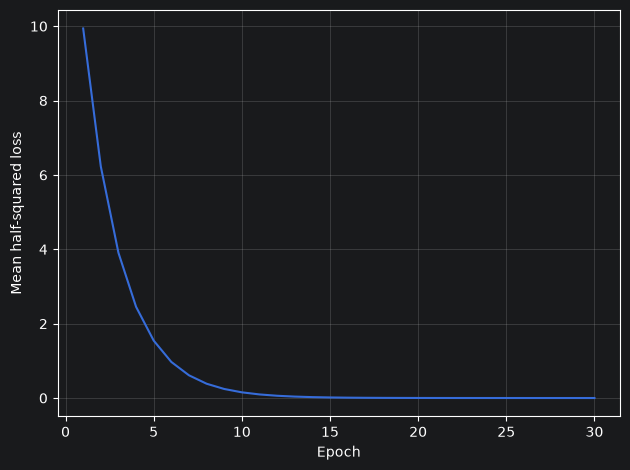

In [3]:
import matplotlib.pyplot as plt

with torch.no_grad():
    learned_w = model[0].weight.detach().reshape(-1)
    learned_b = model[0].bias.detach()

    print("学到的权重:", learned_w)
    print("权重误差:", learned_w - true_w)
    print("学到的偏置:", learned_b)
    print("偏置误差:", learned_b - true_b)

    predictions = model(features)
    assert predictions.shape == labels.shape

    manual_loss = ((predictions - labels) ** 2 / 2).mean()
    framework_loss = loss_fn(predictions, labels) / 2
    assert torch.allclose(manual_loss, framework_loss)
    print("损失一致性检查通过:", framework_loss.item())

plt.plot(range(1, len(framework_loss_history) + 1),
         framework_loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean half-squared loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## 学习率对照实验与线性回归项目验收

#### 1. 先明确实验问题

我们要回答
```
在其他条件相同的情况下, 学习率怎样影响这次线性回归训练?
```

比较三组:
```
learning_rates = [0.003, 0.03, 0.3]
```

不能先认定`0.3`一定最好, 较小学习率可能进展慢, 较大学习率可能下降快, 也可能过大而不稳定, 最终以实验结果为准

**受控实验 (controlled experiment)**: 尽量保持其他条件一致, 只改变我们要研究的因素.
<table>
<tr><th>该表的条件</th><th>固定的条件</th></tr>
<tr><td>学习率</td><td>同一份数据, 相同初始参数, 相同批次顺序, 相同模型</td></tr>
<tr><td></td><td>batch_size=128, epochs=30, 平均半平方损失, CPU</td></tr>
</table>

每组仍然是每轮8次更新, 共240次更新. 我们比较的是相同训练预算下的结果.

#### 2. 每组都必须从同一个起点重新训练

不能这样做:
```
先用 0.003 训练模型
接着把同一个模型改成 0.03，继续训练
最后改成 0.3，再继续训练
```

后两组已经继承前两组的学习结果, 不再是公平的独立比较.

正确方式是:
```
torch.manual_seed(42)
initial_weight = torch.randn(1, 2) * 0.01
initial_bias = torch.zeros(1)
```

先在训练外生成一次, 保存下来:
```
torch.manual_seed(42)
initial_weight = torch.randn(1, 2) * 0.01
initial_bias = torch.zeros(1)
```

每组新建模型后, 用`copy_()`把这些数值复制进去
```
with torch.no_grad():
    model[0].weight.copy_(initial_weight)
    model[0].bias.copy_(initial_bias)
```

`copy_()`是原地复制数值. 随后训练修改的是模型自己的参数, 不是这份保存的初始模板.

#### 3. 打乱顺序也要对应一致

即使数据相同, 不同的批次也可能影响训练轨迹.

这里认识`torch.Generator`: 管理随机数状态的对象, 可以给`DataLoader`提供独立的随机数来源. 它不是之前使用`yield`的Python生成器, 只是英文名称相同.

每组实验开始时, 都重新创建:
```
g = torch.Generator().manual_seed(123)

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    generator=g,
    num_workers=0,
)
```

这样, 在当前相同环境和相同遍历方式下:
- A组第一轮与B组第一轮的样本顺序对应一致.
- A组第二轮与B组第二轮也对应一致.
- 同一组内部, 不要求第一轮和第二轮顺序相同; 随机数状态会继续向前推进.

因此, `g`在每组开始时创建一次, 不是在每个epoch开始时重新创建, 也不要让三组公用一个已经使用过的`g`.

#### 4. 这次记录什么

每组记录:
- **训练前的损失**: 记作epoch 0, 检查三组起点是否一致.
- 每轮结束的全训练集平均半平方损失.
- 第30轮的权重误差, 偏置误差.
- 三条曲线放在同一张图里, 比较下降速度和稳定性.

结论只限于**本数据, 本模型, 本训练预算**, 不能据此断言某个学习率适用于所有任务.

---
## 把实验落实成代码

#### 先准备共同起点
复用已导入的`torch, nn, TensorDataset, DataLoader`:

In [4]:
torch.manual_seed(42)

initial_weight = torch.randn(1, 2) * 0.01
initial_bias = torch.zeros(1)
dataset = TensorDataset(features, labels)

learning_rates = [0.003, 0.03, 0.3]

#### 每次调用函数, 独立训练一组

注意这里不再使用之前已经训练好的`model`.

In [5]:
def run_experiment(lr):
    model = nn.Sequential(nn.Linear(2, 1))
    with torch.no_grad():
        model[0].weight.copy_(initial_weight)
        model[0].bias.copy_(initial_bias)

    g = torch.Generator().manual_seed(123)
    loader = DataLoader(
        dataset, batch_size=128, shuffle=True,
        generator=g, num_workers=0,
    )

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = []

    # epoch 0：尚未更新任何参数
    with torch.no_grad():
        initial_loss = loss_fn(model(features), labels) / 2
        history.append(initial_loss.item())

    for epoch in range(30):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()  # TODO：清除旧梯度
            predictions = model(X_batch)  # TODO：预测
            assert predictions.shape == y_batch.shape
            loss = loss_fn(predictions, y_batch) / 2  # TODO：平均半平方损失
            loss.backward()  # TODO：反向传播
            optimizer.step()  # TODO：更新参数

        with torch.no_grad():
            train_loss = loss_fn(model(features), labels) / 2
            history.append(train_loss.item())

    return {
        "lr": lr,
        "history": history,
        "weight": model[0].weight.detach().reshape(-1).clone(),
        "bias": model[0].bias.detach().clone(),
    }

results = [run_experiment(lr) for lr in learning_rates]

学习率: 0.003
初始损失: 15.87874031
最终损失: 3.99188280
权重误差: tensor([-1.0932,  1.6931])
偏置误差: tensor([-2.0761])

学习率: 0.03
初始损失: 15.87874031
最终损失: 0.00006623
权重误差: tensor([-0.0035,  0.0031])
偏置误差: tensor([-0.0033])

学习率: 0.3
初始损失: 15.87874031
最终损失: 0.00004992
权重误差: tensor([-1.4186e-05,  7.5340e-05])
偏置误差: tensor([0.0002])



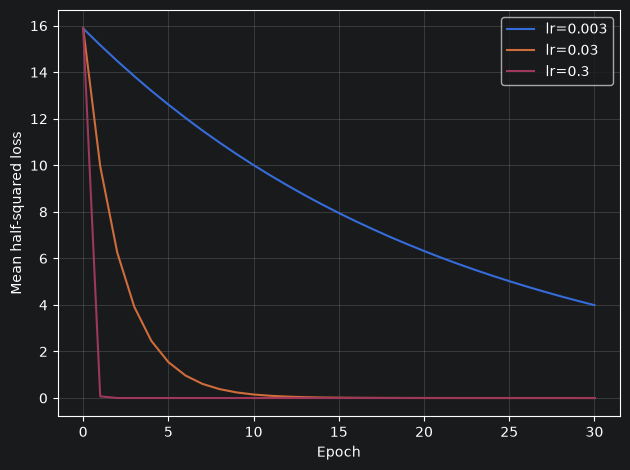

In [6]:
import matplotlib.pyplot as plt

starts = [r["history"][0] for r in results]
assert all(abs(value - starts[0]) < 1e-6 for value in starts)

for r in results:
    history = r["history"]
    assert len(history) == 31

    print(f"学习率: {r['lr']}")
    print(f"初始损失: {history[0]:.8f}")
    print(f"最终损失: {history[-1]:.8f}")
    print("权重误差:", r["weight"] - true_w)
    print("偏置误差:", r["bias"] - true_b)
    print()

    plt.plot(range(len(history)), history, label=f"lr={r['lr']}")

plt.xlabel("Epoch")
plt.ylabel("Mean half-squared loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**学习率会影响有限轮数后的误差**

学习率会影响下降速度, 稳定性, 以及固定训练预算后的误差; 但并不是学习率越大, 最终误差就一定越小.

**不能说学习率越大越好**

过的的更新步长可能引起震荡或发散. 另外, 本次实验只使用一个数据集, 一个初始化和固定训练预算, 结论不能推广到所有任务.